In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [139]:
def load_image(image_path, grayscale=False):
    if grayscale:
        return cv2.imread(image_path, cv2.IMREAD_GRAYSCALE) if image_path else print("Image path is empty.")
    else:
        img = cv2.imread(image_path)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else print("Image not found or could not be loaded.")


def detect_and_describe_sift(image):
    
    sift = cv2.SIFT_create(
        contrastThreshold=0.027,
        edgeThreshold=6,
        sigma=1,
        nOctaveLayers=6,
    )

    kp, des = sift.detectAndCompute(image, None)

    return kp, des

# A function to find correspondences between two sets of keypoints and descriptors
'''CrossCheck e Lowe's ratio sono mutualmente esclusivi perchè CrossCheck forza ad usare bf.match
e quindi non permette di usare il KNN. Se si vuole usare il KNN, bisogna impostare cross_check=False.
In questo caso, si usa il KNN per trovare i due migliori match per ogni descrittore e poi si applica il test di Lowe's ratio.'''
def kp_matching_bf(des1, des2, norm_type=cv2.NORM_L2, cross_check=False, lowe_ratio=0.75):
    bf = cv2.BFMatcher(norm_type, crossCheck=cross_check)

    if cross_check:
        # Simple matching: only best match with crossCheck
        all_matches = bf.match(des1, des2)
        good_matches = sorted(all_matches, key=lambda x: x.distance)
    else:
        # KNN matching + Lowe's ratio test
        if len(des1) <= 1 or len(des2) <= 1:
            return [], []
        matches = bf.knnMatch(des1, des2, k=2)
        if matches is None or len(matches) == 0:
            return [], []
        all_matches = [] 
        good_matches = []
        for m, n in matches:
            all_matches.append(m)
            if m.distance < lowe_ratio * n.distance:
                good_matches.append(m)


    return all_matches, good_matches


# Find model object within scene image
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)

    return M, mask


def perform_template_matching_rot_scale(scene_img, template_img, des_model, hysteresys_th, method=cv2.TM_CCOEFF_NORMED, angles=range(-6, 7, 2), scales=np.linspace(0.95, 1.05, 5)):

    low_threshold, high_threshold = hysteresys_th

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        # Ridimensiona il template
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            # Ruota il template scalato
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            # Salta se il template diventa più grande della scena
            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            # Esegui il template matching
            #weighted_mask = create_weight_mask(rotated_template.shape, axis='horizontal', sigma_ratio=0.4)
            #result, min_val, max_val, min_loc, max_loc = weighted_zncc(rotated_template, scene_gray, weighted_mask)
            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
                match_val = -min_val  # Per coerenza, invertiamo SQDIFF
                top_left = min_loc
            else:
                match_val = max_val
                top_left = max_loc

            if match_val > best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0

    # Compute corners of the current box
    bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)

    corners = np.array([
        [list(top_left_best)],
        [list((top_left_best[0], bottom_right_best[1]))],
        [list(bottom_right_best)],
        [list((bottom_right_best[0], top_left_best[1]))]
    ])
    print(f"Best val: {best_match_val}")
    matched = False
    detected = False
    if best_match_val >= high_threshold:
        matched = True
        detected = True
        print("Match found above highthreshold.")
    elif best_match_val < low_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} below low threshold {low_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        # Match descriptors of the box with the model
        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        mul_factor = (1-best_match_val)+low_threshold
        min_matches = int(0.125 * len(des_model) * mul_factor)

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. Match value: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. No match found. Match value: {best_match_val}.")

    if matched: # togliere matched  e fare il controllo corners ==  None
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected  # Nessun match sopra la soglia


def extract_template_from_corners(image, corners):
    # Assicura che corners sia nella forma corretta
    corners = corners.reshape(-1, 2).astype(np.int32)

    # Trova i limiti del rettangolo che contiene tutti i corner
    x_min = np.min(corners[:, 0])
    y_min = np.min(corners[:, 1])
    x_max = np.max(corners[:, 0])
    y_max = np.max(corners[:, 1])

    # Ritaglia la regione rettangolare direttamente dall'immagine
    cropped_region = image[y_min:y_max, x_min:x_max]

    return cropped_region


def show_keypoints(image, keypoints):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_keypoints)
    plt.axis('off')
    plt.show()

def show_correspondences(image1, image2, kp1, kp2, matches):
    img_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(15, 10))
    plt.imshow(img_matches)
    plt.axis('off')
    plt.show()

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

def draw_matched_rectangle(image,corners):

    image_with_rectangle = image.copy()
    cv2.polylines(image_with_rectangle, [corners], True, (0, 255, 0), 2)
    return image_with_rectangle

'''# A function to remove the detected object from the scene image
def remove_object_from_scene(img_scene, corners):
    # Create a mask for the detected object
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [corners], (255))

    # Invert the mask to keep the background
    mask_inv = cv2.bitwise_not(mask)

    # Remove the object from the scene image
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object'''


def remove_object_from_scene(img_scene, corners, shrink_ratio=0.75):

    corners_reshaped = corners.reshape(-1, 2)
    # Calcola bounding box axis-aligned
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    # Centroide geometrico
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    # Determina asse corto (0 = x, 1 = y)
    if width < height:
        shrink_axis = 0  # shrink solo lungo X
    else:
        shrink_axis = 1  # shrink solo lungo Y

    # Applica shrink solo lungo asse corto
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera e rimuove l'oggetto
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)
    mask_inv = cv2.bitwise_not(mask)
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object

def warp_to_rect(image, corners):
    # Assicura che corners sia (4, 2)
    corners = corners.reshape(4, 2).astype(np.float32)

    # Ordina i punti in ordine: top-left, top-right, bottom-right, bottom-left
    def order_points(pts):
        rect = np.zeros((4, 2), dtype="float32")
        s = pts.sum(axis=1)
        rect[0] = pts[np.argmin(s)]      # Top-left
        rect[2] = pts[np.argmax(s)]      # Bottom-right

        diff = np.diff(pts, axis=1)
        rect[1] = pts[np.argmin(diff)]   # Top-right
        rect[3] = pts[np.argmax(diff)]   # Bottom-left
        return rect

    rect = order_points(corners)
    (tl, tr, br, bl) = rect

    # Calcola la larghezza massima e altezza massima del nuovo rettangolo
    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxWidth = int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxHeight = int(max(heightA, heightB))

    # Definisci i punti della destinazione (rettangolo perfetto)
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ], dtype="float32")

    # Calcola la trasformazione prospettica e applicala
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    return warped


def remove_object_from_scene2(img_scene, corners, shrink_ratio=0.65):

    corners_reshaped = corners.reshape(-1, 2)
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    shrink_axis = 0 if width < height else 1

    # Ridimensiona il poligono verso il centroide
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera della regione da "rimuovere"
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)

    # Crea rumore casuale della stessa dimensione dell'immagine
    noise = np.random.randint(0, 256, img_scene.shape, dtype=np.uint8)

    # Applica la maschera per inserire il rumore solo nell'area target
    img_result = img_scene.copy()
    img_result[mask == 255] = noise[mask == 255]

    return img_result



In [140]:
def rotate_image(image, angle, center=None):
    h, w = image.shape[:2]
    if center is None:
        center = (w / 2, h / 2)
    rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(image, rot_mat, (w, h), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return rotated, rot_mat


In [141]:
def perform_template_matching_rot_scale_ssd(scene_img, template_img, des_model, hysteresys_th,
                                            method=cv2.TM_SQDIFF_NORMED,
                                            angles=range(-6, 7, 2),
                                            scales=np.linspace(0.95, 1.05, 5)):
    def rotate_image(image, angle, center=None):
        h, w = image.shape[:2]
        if center is None:
            center = (w / 2, h / 2)
        rot_mat = cv2.getRotationMatrix2D(center, angle, 1.0)
        rotated = cv2.warpAffine(image, rot_mat, (w, h), flags=cv2.INTER_LINEAR,
                                 borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        return rotated, rot_mat

    low_threshold, high_threshold = hysteresys_th

    # Converti in grayscale se necessario
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = np.inf  # perché cerchiamo il minimo in SSD
    best_match_loc = None
    best_template_shape = None
    best_rot_mat_scene = None
    best_angle = None
    best_scale = None

    for scale in scales:
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            scene_rotated, rot_mat_scene = rotate_image(scene_gray, -angle)

            if (scaled_template.shape[0] > scene_rotated.shape[0]) or (scaled_template.shape[1] > scene_rotated.shape[1]):
                continue

            result = cv2.matchTemplate(scene_rotated, scaled_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            # SSD: valori minori sono migliori
            match_val = min_val
            top_left = min_loc

            if match_val < best_match_val:
                best_match_val = match_val
                best_angle = angle
                best_scale = scale
                best_match_loc = min_loc
                best_template_shape = scaled_template.shape
                best_rot_mat_scene = rot_mat_scene

    # Se nessun match è stato trovato
    if best_match_loc is None:
        return None, best_match_val, False

    # Calcolo centro della scena (uguale a quello usato per ruotarla)
    h_scene, w_scene = scene_gray.shape
    center = (w_scene / 2, h_scene / 2)

    # Inversa della matrice di rotazione
    rot_mat_inv = cv2.invertAffineTransform(best_rot_mat_scene)

    # Trova top-left originale
    top_left = np.array([[best_match_loc]], dtype=np.float32)
    top_left_orig = cv2.transform(top_left, rot_mat_inv)[0][0]

    # Calcola gli altri corner del bounding box
    w, h = best_template_shape[1], best_template_shape[0]
    box = np.array([
        [0, 0],
        [w, 0],
        [w, h],
        [0, h]
    ], dtype=np.float32)

    box_rotated = cv2.transform(np.array([box + best_match_loc]), rot_mat_inv)[0]
    corners = box_rotated.astype(int)

    print(f"Best SSD val: {best_match_val}")
    matched = False
    detected = False

    if best_match_val <= low_threshold:  # SSD: match buoni = valori piccoli
        matched = True
        detected = True
        print("Match found below low threshold (SSD).")
    elif best_match_val > high_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} above high threshold {high_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        # Debug sulla patch estratta
        if current_box is None:
            print("ERROR: Patch extraction failed (None returned).")
            return corners, best_match_val, False

        if current_box.size == 0:
            print("ERROR: Extracted patch has zero size.")
            return corners, best_match_val, False

        if current_box.ndim == 3:
            current_box = cv2.cvtColor(current_box, cv2.COLOR_BGR2GRAY)

        if current_box.dtype != np.uint8:
            print(f"WARNING: Patch has dtype={current_box.dtype}, converting to uint8.")
            current_box = current_box.astype(np.uint8)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        mul_factor = (1+best_match_val) + low_threshold  # SSD: peggiore = valore alto
        #min_matches = int(0.125 * len(des_model) * mul_factor)
        min_matches = int(0.095 * len(des_model) * mul_factor)

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. SSD: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. SSD: {best_match_val}.")

    if matched:
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected


In [142]:

def main(model_path, scene_path, 
         grayscale=False,
         min_match_pct=0.1,
         cross_check=False, 
         lowe_ratio=0.8, 
         hysteresys_th=(0.45, 0.8),
         method=cv2.RANSAC, 
         ransacReprojThreshold=5.0, 
         similarity_measure=cv2.TM_CCOEFF_NORMED):

    detections = 0

    model_img = load_image(model_path, grayscale=grayscale)
    scene_img = load_image(scene_path, grayscale=grayscale)

    scene = scene_img.copy()

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img)
    kp_scene, des_scene = detect_and_describe_sift(scene_img)

    if kp_model is None or kp_scene is None:
        print("No keypoints or descriptors found in the model or scene image.")
        return

    # Match keypoints
    all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, cross_check=cross_check, lowe_ratio=lowe_ratio)
    
    # Find homography
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches)
    if M is None:
        print("Homography could not be computed. No instances detected.")
        return
    else:
        print(f"Homography computed successfully")
    
    detections += 1

    # Draw bounding box around the detected model in the scene
    corners, img_scene_with_box = draw_bounding_box(scene, model_img, M)

    # Compute ROI from the corners
    # roi_scene = compute_roi(scene_img, corners)

    # Extract the template to permit template matching
    #template = extract_template_from_corners(scene_img, corners)
    template = warp_to_rect(scene_img, corners)
    plt.imshow(template)
    plt.show()
    i=0
    while i<20:
        # Mask the object detected
        scene_img = remove_object_from_scene(scene_img, corners)
        # plt.imshow(scene_img)
        # plt.show()

        # Perform template matching in the ROI
        #corners, match_val, detected = perform_template_matching_rot_scale(scene_img, template, des_model, hysteresys_th, method=similarity_measure)
        corners, match_val, detected = perform_template_matching_rot_scale_ssd(scene_img, template, des_model, hysteresys_th, method=cv2.TM_SQDIFF_NORMED)
        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{hysteresys_th[0]}.")
            break

        if detected:
            detections += 1
            scene = draw_matched_rectangle(scene, corners)

        i += 1

    print(f"Total instances detected: {detections}")
    if detections > 0:
        plt.imshow(scene)
        plt.show()



Homography computed successfully


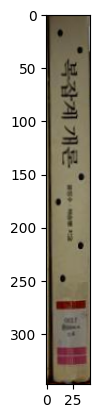

Best SSD val: 0.10537528246641159
Not enough matches: 30/103. SSD: 0.10537528246641159.
Best SSD val: 0.14199969172477722
New match found with 108/107 good matches. SSD: 0.14199969172477722.
Best SSD val: 0.15272864699363708
Not enough matches: 38/108. SSD: 0.15272864699363708.
Best SSD val: 0.154192715883255
Not enough matches: 37/108. SSD: 0.154192715883255.
Best SSD val: 0.2241307944059372
Not enough matches: 35/114. SSD: 0.2241307944059372.
Best SSD val: 0.261303186416626
Not enough matches: 60/118. SSD: 0.261303186416626.
Best SSD val: 0.26517993211746216
Not enough matches: 51/118. SSD: 0.26517993211746216.
Best SSD val: 0.28164514899253845
Value 0.28164514899253845 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.28164514899253845/0.03.
Total instances detected: 2


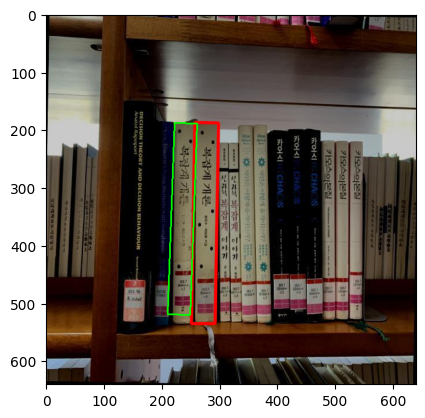

In [145]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.075
hyst_th = (0.03, 0.27)
# 19-7
# 15-11
# 16-11
# 27-2
scene_path = f'./dataset/scenes/scene_15.jpg'
model_path = f'./dataset/models/model_11.png'

main(model_path, scene_path, 
    grayscale=grayscale, 
    hysteresys_th=hyst_th, 
    min_match_pct=min_match_pct,
    cross_check=crosscheck, 
    lowe_ratio=lowe_ratio, 
    method=cv2.RANSAC, 
    ransacReprojThreshold=5.0, 
    similarity_measure=cv2.TM_CCOEFF_NORMED)

--------------------------------- Processing scene 0 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

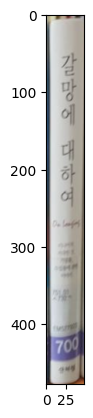

Best SSD val: 0.04487425461411476
Not enough matches: 20/58. SSD: 0.04487425461411476.
Best SSD val: 0.04870828986167908
New match found with 216/58 good matches. SSD: 0.04870828986167908.
Best SSD val: 0.06891454756259918
Not enough matches: 29/60. SSD: 0.06891454756259918.
Best SSD val: 0.08344602584838867
Not enough matches: 24/60. SSD: 0.08344602584838867.
Best SSD val: 0.09974216669797897
Not enough matches: 29/61. SSD: 0.09974216669797897.
Best SSD val: 0.09979970753192902
Not enough matches: 33/61. SSD: 0.09979970753192902.
Best SSD val: 0.18058428168296814
Not enough matches: 9/66. SSD: 0.18058428168296814.
Best SSD val: 0.37694498896598816
Value 0.37694498896598816 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.37694498896598816/0.03.
Total instances detected: 2


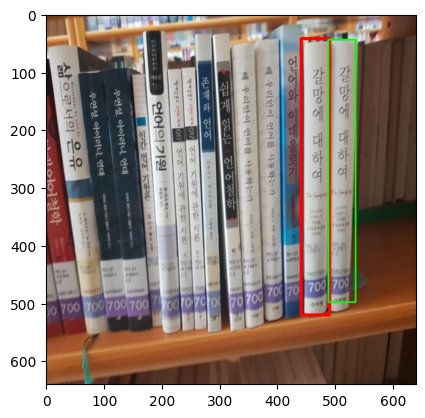

-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 2 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be com

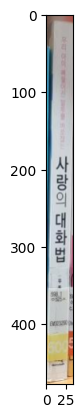

Best SSD val: 0.05329695716500282
Not enough matches: 43/89. SSD: 0.05329695716500282.
Best SSD val: 0.07526861876249313
Not enough matches: 38/91. SSD: 0.07526861876249313.
Best SSD val: 0.10435234755277634
Not enough matches: 32/94. SSD: 0.10435234755277634.
Best SSD val: 0.10651277005672455
Not enough matches: 41/94. SSD: 0.10651277005672455.
Best SSD val: 0.11148197203874588
Not enough matches: 32/94. SSD: 0.11148197203874588.
Best SSD val: 0.11228764057159424
Not enough matches: 39/94. SSD: 0.11228764057159424.
Best SSD val: 0.11958997696638107
Not enough matches: 28/95. SSD: 0.11958997696638107.
Best SSD val: 0.1234983578324318
Not enough matches: 44/95. SSD: 0.1234983578324318.
Best SSD val: 0.13723263144493103
Not enough matches: 29/96. SSD: 0.13723263144493103.
Best SSD val: 0.16663417220115662
Not enough matches: 29/99. SSD: 0.16663417220115662.
Best SSD val: 0.20184601843357086
Not enough matches: 27/102. SSD: 0.20184601843357086.
Best SSD val: 0.2397002875804901
Not enough 

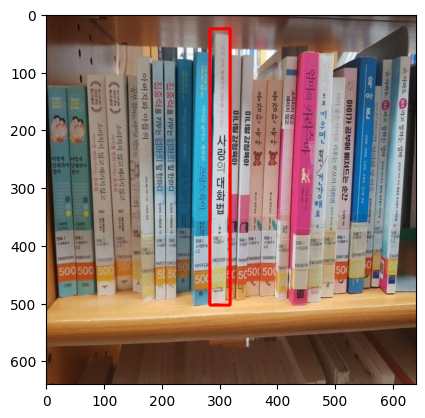

-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 3 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be co

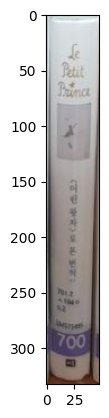

Best SSD val: 0.028279177844524384
Match found below low threshold (SSD).
Best SSD val: 0.03437831252813339
Not enough matches: 23/95. SSD: 0.03437831252813339.
Best SSD val: 0.044406600296497345
Not enough matches: 23/95. SSD: 0.044406600296497345.
Best SSD val: 0.04819593206048012
Not enough matches: 32/96. SSD: 0.04819593206048012.
Best SSD val: 0.06512900441884995
Not enough matches: 17/97. SSD: 0.06512900441884995.
Best SSD val: 0.06736010313034058
Not enough matches: 15/97. SSD: 0.06736010313034058.
Best SSD val: 0.13522028923034668
Not enough matches: 26/104. SSD: 0.13522028923034668.
Best SSD val: 0.20026279985904694
Not enough matches: 17/109. SSD: 0.20026279985904694.
Best SSD val: 0.20031654834747314
Not enough matches: 20/109. SSD: 0.20031654834747314.
Best SSD val: 0.27929219603538513
Value 0.27929219603538513 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.27929219603538513/0.03.
Total instances detected:

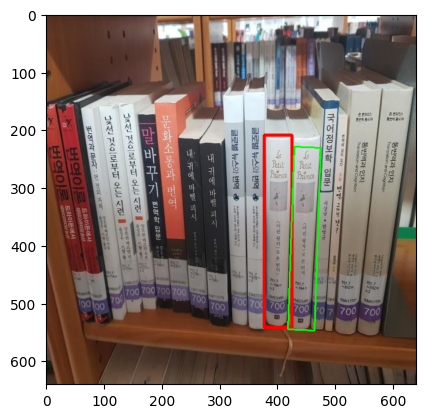

-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 4 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be c

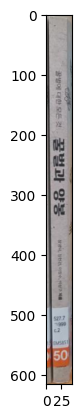

Best SSD val: 0.08101896941661835
New match found with 337/163 good matches. SSD: 0.08101896941661835.
Best SSD val: 0.11938344687223434
ERROR: Extracted patch has zero size.
Best SSD val: 0.12872153520584106
Not enough matches: 75/170. SSD: 0.12872153520584106.
Best SSD val: 0.16551841795444489
Not enough matches: 87/175. SSD: 0.16551841795444489.
Best SSD val: 0.2199918031692505
Not enough matches: 75/183. SSD: 0.2199918031692505.
Best SSD val: 0.24377506971359253
Not enough matches: 92/187. SSD: 0.24377506971359253.
Best SSD val: 0.25578054785728455
Not enough matches: 88/188. SSD: 0.25578054785728455.
Best SSD val: 0.4227050542831421
Value 0.4227050542831421 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.4227050542831421/0.03.
Total instances detected: 2


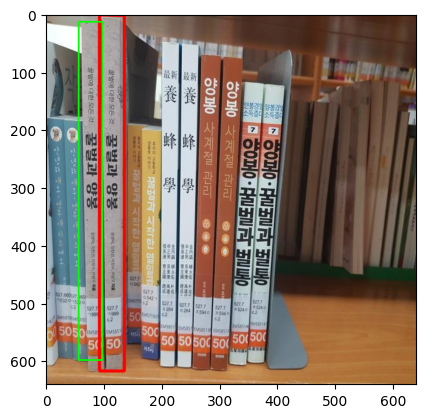

-------- Processing model 15 --------
Homography computed successfully


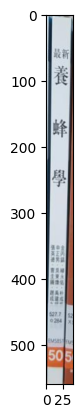

Best SSD val: 0.12456417083740234
New match found with 393/166 good matches. SSD: 0.12456417083740234.
Best SSD val: 0.16926392912864685
Not enough matches: 69/172. SSD: 0.16926392912864685.
Best SSD val: 0.190125972032547
Not enough matches: 62/175. SSD: 0.190125972032547.
Best SSD val: 0.2464698851108551
Not enough matches: 57/183. SSD: 0.2464698851108551.
Best SSD val: 0.2691391706466675
Not enough matches: 75/186. SSD: 0.2691391706466675.
Best SSD val: 0.29840654134750366
Value 0.29840654134750366 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.29840654134750366/0.03.
Total instances detected: 2


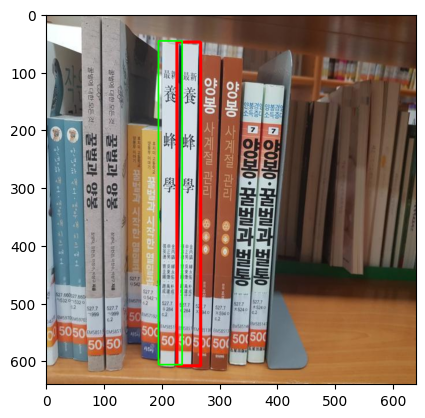

-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 5 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be 

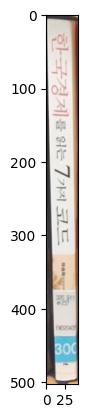

Best SSD val: 0.1135350689291954
Not enough matches: 57/133. SSD: 0.1135350689291954.
Best SSD val: 0.12475738674402237
Not enough matches: 74/134. SSD: 0.12475738674402237.
Best SSD val: 0.1644410490989685
Not enough matches: 40/139. SSD: 0.1644410490989685.
Best SSD val: 0.1911201775074005
ERROR: Extracted patch has zero size.
Best SSD val: 0.2702259421348572
Value 0.2702259421348572 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.2702259421348572/0.03.
Total instances detected: 1


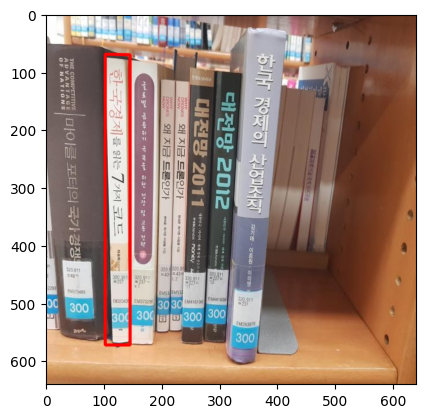

-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 6 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not b

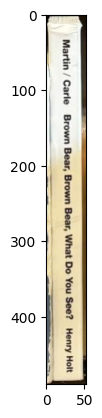

Best SSD val: 0.16606952250003815
Not enough matches: 79/153. SSD: 0.16606952250003815.
Best SSD val: 0.2060832679271698
Not enough matches: 96/158. SSD: 0.2060832679271698.
Best SSD val: 0.2324739545583725
Not enough matches: 28/161. SSD: 0.2324739545583725.
Best SSD val: 0.2731628715991974
Value 0.2731628715991974 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.2731628715991974/0.03.
Total instances detected: 1


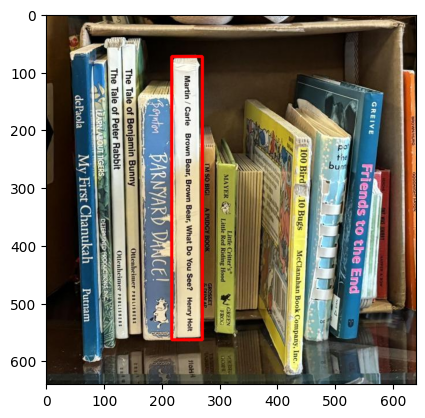

--------------------------------- Processing scene 7 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

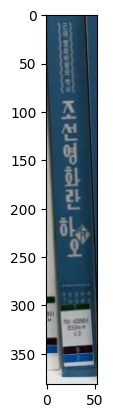

Best SSD val: 0.26668229699134827
New match found with 318/120 good matches. SSD: 0.26668229699134827.
Best SSD val: 0.2704505920410156
Value 0.2704505920410156 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.2704505920410156/0.03.
Total instances detected: 2


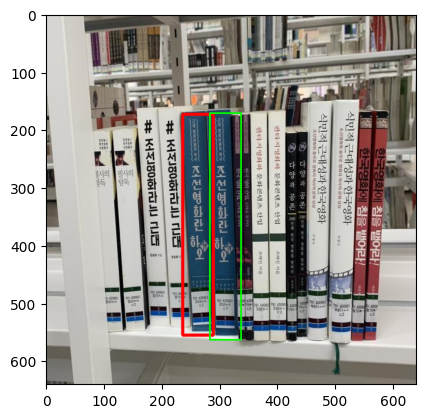

-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 8 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be compu

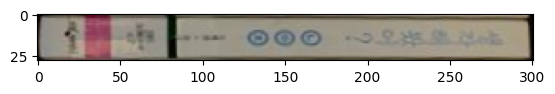

Best SSD val: 0.024967249482870102
Match found below low threshold (SSD).
Best SSD val: 0.034670330584049225
New match found with 97/62 good matches. SSD: 0.034670330584049225.
Best SSD val: 0.05435721576213837
Not enough matches: 16/63. SSD: 0.05435721576213837.
Best SSD val: 0.05446168780326843
Not enough matches: 12/63. SSD: 0.05446168780326843.
Best SSD val: 0.05332201346755028
Not enough matches: 31/63. SSD: 0.05332201346755028.
Best SSD val: 0.058812372386455536
Not enough matches: 15/64. SSD: 0.058812372386455536.
Best SSD val: 0.0608198419213295
New match found with 84/64 good matches. SSD: 0.0608198419213295.
Best SSD val: 0.060905296355485916
Not enough matches: 20/64. SSD: 0.060905296355485916.
Best SSD val: 0.061698298901319504
Not enough matches: 14/64. SSD: 0.061698298901319504.
Best SSD val: 0.07252264022827148
Not enough matches: 23/65. SSD: 0.07252264022827148.
Best SSD val: 0.07388639450073242
Not enough matches: 15/65. SSD: 0.07388639450073242.
Best SSD val: 0.074248

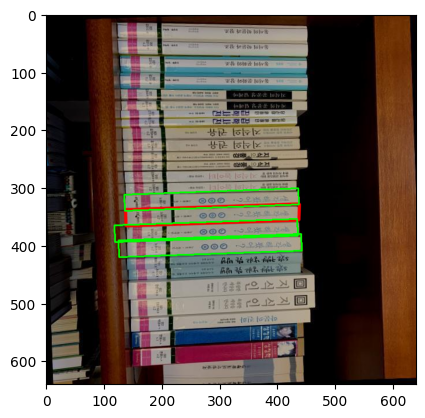

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 10 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

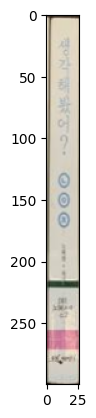

Best SSD val: 0.021996431052684784
Match found below low threshold (SSD).
Best SSD val: 0.026060957461595535
Match found below low threshold (SSD).
Best SSD val: 0.03341573849320412
Not enough matches: 13/62. SSD: 0.03341573849320412.
Best SSD val: 0.03538239002227783
Not enough matches: 10/62. SSD: 0.03538239002227783.
Best SSD val: 0.03581907972693443
Not enough matches: 4/62. SSD: 0.03581907972693443.
Best SSD val: 0.03786453604698181
Not enough matches: 33/62. SSD: 0.03786453604698181.
Best SSD val: 0.038316674530506134
New match found with 100/63 good matches. SSD: 0.038316674530506134.
Best SSD val: 0.0384318046271801
Not enough matches: 19/63. SSD: 0.0384318046271801.
Best SSD val: 0.04118291661143303
Not enough matches: 21/63. SSD: 0.04118291661143303.
Best SSD val: 0.04574348032474518
Not enough matches: 14/63. SSD: 0.04574348032474518.
Best SSD val: 0.046357959508895874
Not enough matches: 32/63. SSD: 0.046357959508895874.
Best SSD val: 0.048577092587947845
Not enough matches

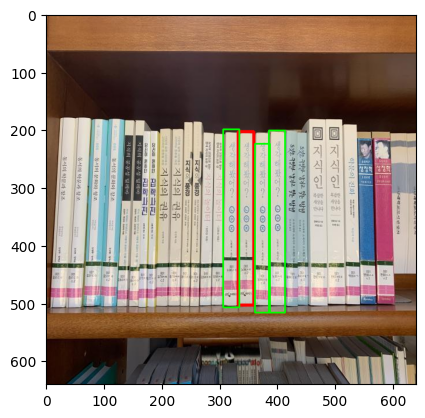

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 11 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

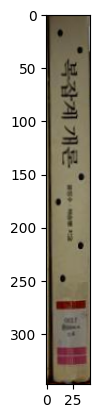

Best SSD val: 0.10537528246641159
Not enough matches: 30/103. SSD: 0.10537528246641159.
Best SSD val: 0.14199969172477722
New match found with 108/107 good matches. SSD: 0.14199969172477722.
Best SSD val: 0.15272864699363708
Not enough matches: 38/108. SSD: 0.15272864699363708.
Best SSD val: 0.154192715883255
Not enough matches: 37/108. SSD: 0.154192715883255.
Best SSD val: 0.2241307944059372
Not enough matches: 35/114. SSD: 0.2241307944059372.
Best SSD val: 0.261303186416626
Not enough matches: 60/118. SSD: 0.261303186416626.
Best SSD val: 0.26517993211746216
Not enough matches: 51/118. SSD: 0.26517993211746216.
Best SSD val: 0.28164514899253845
Value 0.28164514899253845 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.28164514899253845/0.03.
Total instances detected: 2


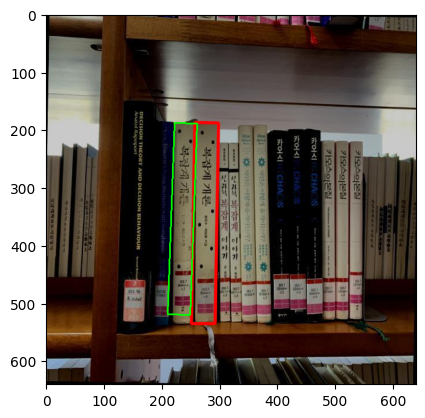

-------- Processing model 12 --------
Homography computed successfully


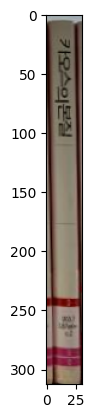

Best SSD val: 0.11264044046401978
Not enough matches: 20/51. SSD: 0.11264044046401978.
Best SSD val: 0.11284378916025162
Not enough matches: 30/51. SSD: 0.11284378916025162.
Best SSD val: 0.1280994713306427
Not enough matches: 27/52. SSD: 0.1280994713306427.
Best SSD val: 0.18381959199905396
Not enough matches: 25/54. SSD: 0.18381959199905396.
Best SSD val: 0.18800963461399078
New match found with 95/54 good matches. SSD: 0.18800963461399078.
Best SSD val: 0.19070656597614288
Not enough matches: 21/55. SSD: 0.19070656597614288.
Best SSD val: 0.23513968288898468
New match found with 77/57 good matches. SSD: 0.23513968288898468.
Best SSD val: 0.2441626787185669
Not enough matches: 20/57. SSD: 0.2441626787185669.
Best SSD val: 0.2890557646751404
Value 0.2890557646751404 above high threshold 0.27. No match found.
No match found during template matching on instance 4. Matching value: 0.2890557646751404/0.03.
Total instances detected: 3


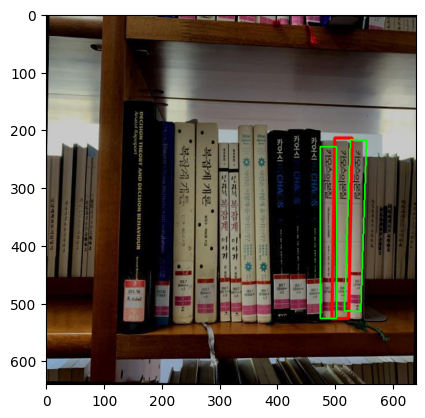

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 16 ---------------------------------
-------- Processing model 0 --------
Homography could not

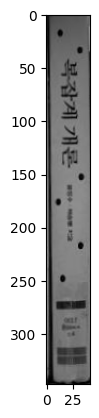

Best SSD val: 0.09624511748552322
Not enough matches: 37/103. SSD: 0.09624511748552322.
Best SSD val: 0.14150597155094147
Not enough matches: 45/107. SSD: 0.14150597155094147.
Best SSD val: 0.14208243787288666
New match found with 113/107 good matches. SSD: 0.14208243787288666.
Best SSD val: 0.1462482213973999
Not enough matches: 40/107. SSD: 0.1462482213973999.
Best SSD val: 0.21924708783626556
Not enough matches: 44/114. SSD: 0.21924708783626556.
Best SSD val: 0.23467916250228882
Not enough matches: 63/115. SSD: 0.23467916250228882.
Best SSD val: 0.24850642681121826
Not enough matches: 55/116. SSD: 0.24850642681121826.
Best SSD val: 0.2610187530517578
Not enough matches: 42/118. SSD: 0.2610187530517578.
Best SSD val: 0.39469271898269653
Value 0.39469271898269653 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.39469271898269653/0.03.
Total instances detected: 2


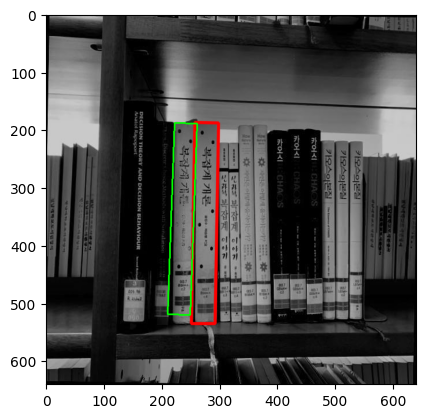

-------- Processing model 12 --------
Homography computed successfully


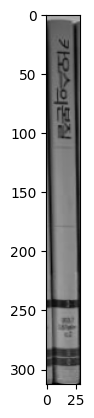

Best SSD val: 0.10544430464506149
Not enough matches: 15/51. SSD: 0.10544430464506149.
Best SSD val: 0.10774993896484375
Not enough matches: 35/51. SSD: 0.10774993896484375.
Best SSD val: 0.1232278123497963
Not enough matches: 25/52. SSD: 0.1232278123497963.
Best SSD val: 0.1501447707414627
Not enough matches: 23/53. SSD: 0.1501447707414627.
Best SSD val: 0.17693080008029938
Not enough matches: 27/54. SSD: 0.17693080008029938.
Best SSD val: 0.17710702121257782
New match found with 85/54 good matches. SSD: 0.17710702121257782.
Best SSD val: 0.22371727228164673
New match found with 85/56 good matches. SSD: 0.22371727228164673.
Best SSD val: 0.2340622991323471
Not enough matches: 29/57. SSD: 0.2340622991323471.
Best SSD val: 0.2671600878238678
Not enough matches: 21/58. SSD: 0.2671600878238678.
Best SSD val: 0.28138425946235657
Value 0.28138425946235657 above high threshold 0.27. No match found.
No match found during template matching on instance 4. Matching value: 0.28138425946235657/0.0

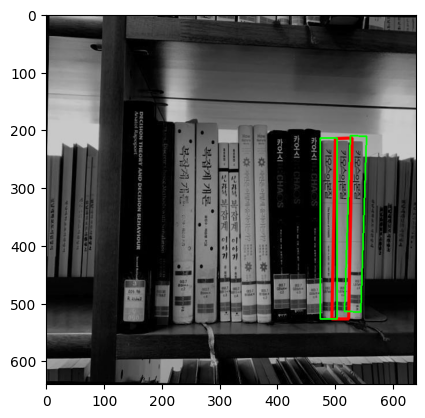

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 17 ---------------------------------
-------- Processing model 0 --------
Homography could not

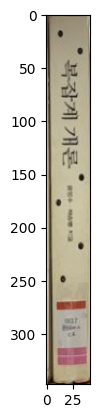

Best SSD val: 0.05886581167578697
Not enough matches: 49/99. SSD: 0.05886581167578697.
Best SSD val: 0.08568903058767319
Not enough matches: 38/102. SSD: 0.08568903058767319.
Best SSD val: 0.0890992283821106
Not enough matches: 61/102. SSD: 0.0890992283821106.
Best SSD val: 0.09807965159416199
New match found with 121/103 good matches. SSD: 0.09807965159416199.
Best SSD val: 0.1169854998588562
Not enough matches: 38/104. SSD: 0.1169854998588562.
Best SSD val: 0.13414926826953888
Not enough matches: 71/106. SSD: 0.13414926826953888.
Best SSD val: 0.13695180416107178
Not enough matches: 45/106. SSD: 0.13695180416107178.
Best SSD val: 0.1484813243150711
Not enough matches: 37/107. SSD: 0.1484813243150711.
Best SSD val: 0.17809468507766724
Not enough matches: 30/110. SSD: 0.17809468507766724.
Best SSD val: 0.2717773914337158
Value 0.2717773914337158 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.2717773914337158/0.03.
Tot

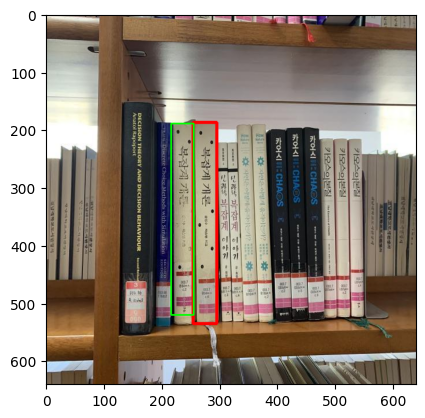

-------- Processing model 12 --------
Homography computed successfully


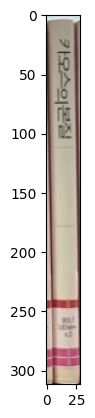

Best SSD val: 0.06709744036197662
Not enough matches: 23/49. SSD: 0.06709744036197662.
Best SSD val: 0.07216861844062805
Not enough matches: 20/49. SSD: 0.07216861844062805.
Best SSD val: 0.08676593750715256
Not enough matches: 26/50. SSD: 0.08676593750715256.
Best SSD val: 0.08886128664016724
Not enough matches: 25/50. SSD: 0.08886128664016724.
Best SSD val: 0.10630930960178375
New match found with 112/51 good matches. SSD: 0.10630930960178375.
Best SSD val: 0.11327890306711197
Not enough matches: 10/51. SSD: 0.11327890306711197.
Best SSD val: 0.13036023080348969
Not enough matches: 18/52. SSD: 0.13036023080348969.
Best SSD val: 0.1487146019935608
Not enough matches: 31/53. SSD: 0.1487146019935608.
Best SSD val: 0.15639671683311462
New match found with 91/53 good matches. SSD: 0.15639671683311462.
Best SSD val: 0.17363841831684113
Not enough matches: 32/54. SSD: 0.17363841831684113.
Best SSD val: 0.18331634998321533
Not enough matches: 19/54. SSD: 0.18331634998321533.
Best SSD val: 0.

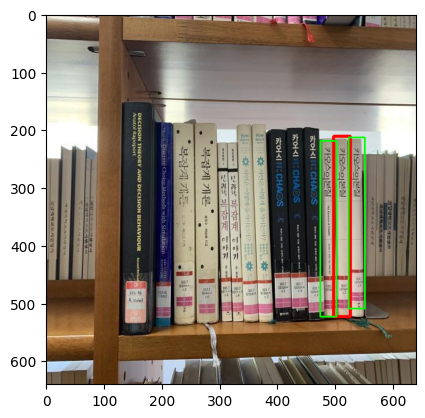

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 18 ---------------------------------
-------- Processing model 0 --------
Homography could not

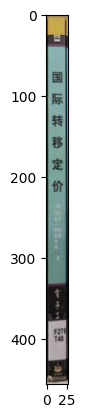

Best SSD val: 0.07896265387535095
New match found with 249/95 good matches. SSD: 0.07896265387535095.
Best SSD val: 0.08203453570604324
New match found with 250/95 good matches. SSD: 0.08203453570604324.
Best SSD val: 0.14156438410282135
Not enough matches: 40/100. SSD: 0.14156438410282135.
Best SSD val: 0.14726626873016357
Not enough matches: 40/101. SSD: 0.14726626873016357.
Best SSD val: 0.15184956789016724
Not enough matches: 48/101. SSD: 0.15184956789016724.
Best SSD val: 0.155615895986557
Not enough matches: 34/102. SSD: 0.155615895986557.
Best SSD val: 0.1594754159450531
Not enough matches: 24/102. SSD: 0.1594754159450531.
Best SSD val: 0.1819002479314804
Not enough matches: 53/104. SSD: 0.1819002479314804.
Best SSD val: 0.18573927879333496
Not enough matches: 32/104. SSD: 0.18573927879333496.
Best SSD val: 0.18594402074813843
Not enough matches: 38/104. SSD: 0.18594402074813843.
Best SSD val: 0.19110740721225739
Not enough matches: 52/105. SSD: 0.19110740721225739.
Best SSD val

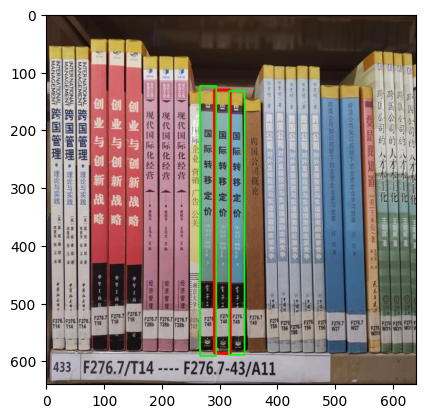

-------- Processing model 9 --------
Homography computed successfully


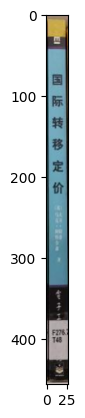

Best SSD val: 0.07786279916763306
New match found with 273/103 good matches. SSD: 0.07786279916763306.
Best SSD val: 0.0848156288266182
New match found with 266/103 good matches. SSD: 0.0848156288266182.
Best SSD val: 0.1360350102186203
Not enough matches: 47/108. SSD: 0.1360350102186203.
Best SSD val: 0.14378538727760315
Not enough matches: 52/109. SSD: 0.14378538727760315.
Best SSD val: 0.14749225974082947
Not enough matches: 42/109. SSD: 0.14749225974082947.
Best SSD val: 0.14952661097049713
Not enough matches: 39/109. SSD: 0.14952661097049713.
Best SSD val: 0.17124861478805542
Not enough matches: 51/111. SSD: 0.17124861478805542.
Best SSD val: 0.1872168332338333
Not enough matches: 36/113. SSD: 0.1872168332338333.
Best SSD val: 0.19045992195606232
Not enough matches: 32/113. SSD: 0.19045992195606232.
Best SSD val: 0.2017892450094223
Not enough matches: 63/114. SSD: 0.2017892450094223.
Best SSD val: 0.20477914810180664
Not enough matches: 49/115. SSD: 0.20477914810180664.
Best SSD v

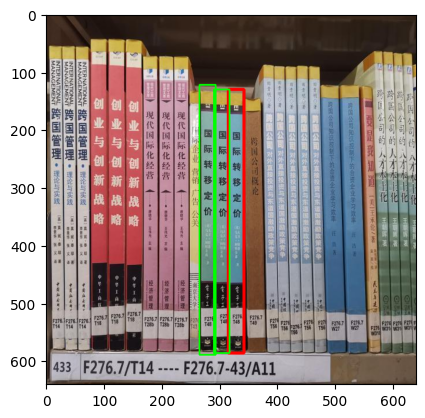

-------- Processing model 10 --------
Homography computed successfully


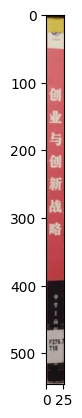

Best SSD val: 0.035318028181791306
New match found with 248/84 good matches. SSD: 0.035318028181791306.
Best SSD val: 0.05001313239336014
New match found with 252/85 good matches. SSD: 0.05001313239336014.
Best SSD val: 0.16128186881542206
Not enough matches: 38/94. SSD: 0.16128186881542206.
Best SSD val: 0.16634100675582886
Not enough matches: 25/94. SSD: 0.16634100675582886.
Best SSD val: 0.18106766045093536
Not enough matches: 41/95. SSD: 0.18106766045093536.
Best SSD val: 0.19926834106445312
Not enough matches: 61/97. SSD: 0.19926834106445312.
Best SSD val: 0.20021358132362366
Not enough matches: 43/97. SSD: 0.20021358132362366.
Best SSD val: 0.21659113466739655
Not enough matches: 41/98. SSD: 0.21659113466739655.
Best SSD val: 0.2392270565032959
Not enough matches: 37/100. SSD: 0.2392270565032959.
Best SSD val: 0.277258038520813
Value 0.277258038520813 above high threshold 0.27. No match found.
No match found during template matching on instance 4. Matching value: 0.27725803852081

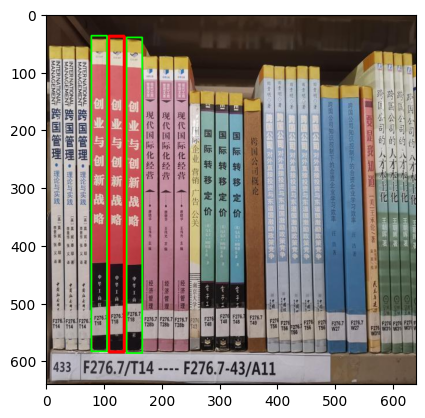

-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography c

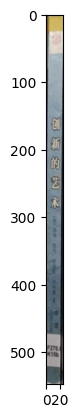

Best SSD val: 0.040507085621356964
New match found with 198/96 good matches. SSD: 0.040507085621356964.
Best SSD val: 0.0646834522485733
New match found with 191/99 good matches. SSD: 0.0646834522485733.
Best SSD val: 0.11272726207971573
Not enough matches: 32/103. SSD: 0.11272726207971573.
Best SSD val: 0.11499007791280746
Not enough matches: 38/103. SSD: 0.11499007791280746.
Best SSD val: 0.11670539528131485
Not enough matches: 36/103. SSD: 0.11670539528131485.
Best SSD val: 0.11776970326900482
Not enough matches: 37/103. SSD: 0.11776970326900482.
Best SSD val: 0.11824079602956772
Not enough matches: 26/103. SSD: 0.11824079602956772.
Best SSD val: 0.12839725613594055
Not enough matches: 28/104. SSD: 0.12839725613594055.
Best SSD val: 0.13037154078483582
Not enough matches: 47/104. SSD: 0.13037154078483582.
Best SSD val: 0.1514500081539154
Not enough matches: 26/106. SSD: 0.1514500081539154.
Best SSD val: 0.15212874114513397
Not enough matches: 28/106. SSD: 0.15212874114513397.
Best S

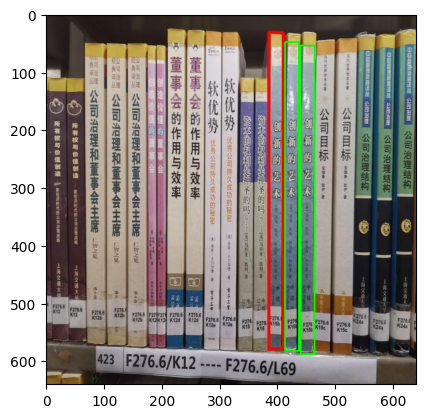

-------- Processing model 7 --------
Homography computed successfully


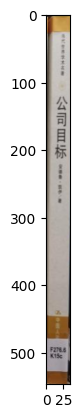

Best SSD val: 0.04258597642183304
New match found with 244/71 good matches. SSD: 0.04258597642183304.
Best SSD val: 0.08161896467208862
Not enough matches: 43/74. SSD: 0.08161896467208862.
Best SSD val: 0.08230704069137573
New match found with 79/74 good matches. SSD: 0.08230704069137573.
Best SSD val: 0.09245431423187256
Not enough matches: 52/74. SSD: 0.09245431423187256.
Best SSD val: 0.09290903061628342
Not enough matches: 72/74. SSD: 0.09290903061628342.
Best SSD val: 0.09563148766756058
Not enough matches: 60/75. SSD: 0.09563148766756058.
Best SSD val: 0.11087078601121902
Not enough matches: 74/76. SSD: 0.11087078601121902.
Best SSD val: 0.11165378242731094
Not enough matches: 59/76. SSD: 0.11165378242731094.
Best SSD val: 0.13897736370563507
Not enough matches: 27/78. SSD: 0.13897736370563507.
Best SSD val: 0.17113076150417328
Not enough matches: 53/80. SSD: 0.17113076150417328.
Best SSD val: 0.18844018876552582
Not enough matches: 47/81. SSD: 0.18844018876552582.
Best SSD val: 

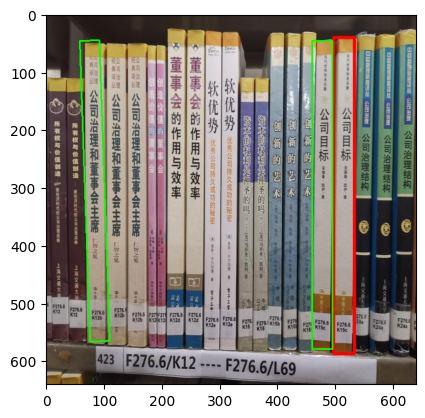

-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography cou

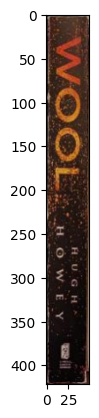

Best SSD val: 0.38769015669822693
Value 0.38769015669822693 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.38769015669822693/0.03.
Total instances detected: 1


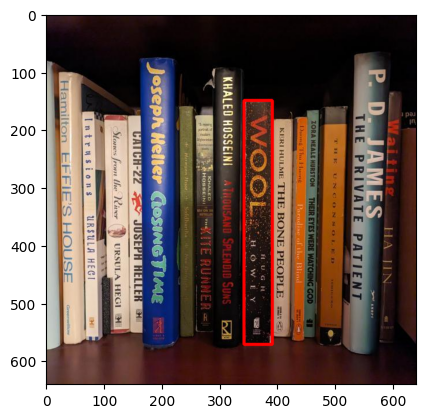

-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could

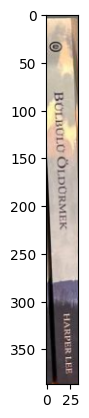

Best SSD val: 0.0439472422003746
New match found with 280/104 good matches. SSD: 0.0439472422003746.
Best SSD val: 0.0850139781832695
Not enough matches: 61/108. SSD: 0.0850139781832695.
Best SSD val: 0.09229403734207153
Not enough matches: 50/108. SSD: 0.09229403734207153.
Best SSD val: 0.09681178629398346
Not enough matches: 37/109. SSD: 0.09681178629398346.
Best SSD val: 0.09663324803113937
Not enough matches: 41/109. SSD: 0.09663324803113937.
Best SSD val: 0.11855290085077286
Not enough matches: 56/111. SSD: 0.11855290085077286.
Best SSD val: 0.1343371570110321
Not enough matches: 38/112. SSD: 0.1343371570110321.
Best SSD val: 0.14244914054870605
Not enough matches: 49/113. SSD: 0.14244914054870605.
Best SSD val: 0.19698141515254974
Not enough matches: 25/119. SSD: 0.19698141515254974.
Best SSD val: 0.20054009556770325
Not enough matches: 49/119. SSD: 0.20054009556770325.
Best SSD val: 0.2365456074476242
Not enough matches: 45/122. SSD: 0.2365456074476242.
Best SSD val: 0.334615677

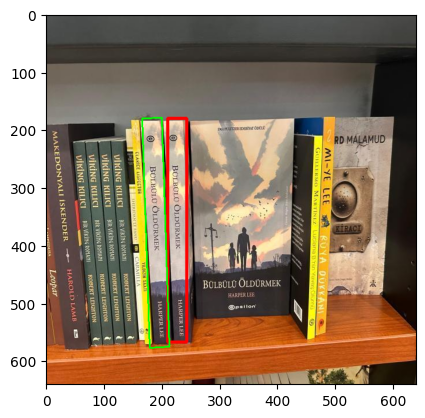

-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography computed successfully


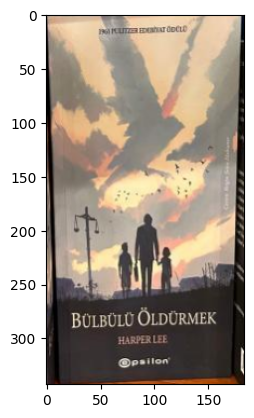

Best SSD val: 0.2204345315694809
Not enough matches: 111/399. SSD: 0.2204345315694809.
Best SSD val: 0.2611328959465027
Not enough matches: 91/412. SSD: 0.2611328959465027.
Best SSD val: 0.44846516847610474
Value 0.44846516847610474 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.44846516847610474/0.03.
Total instances detected: 1


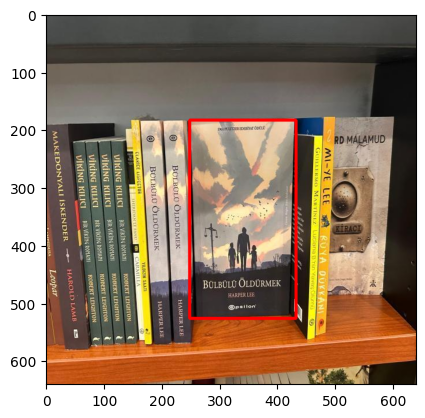

-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could 

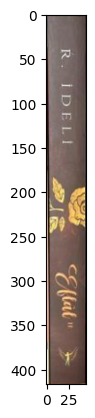

Best SSD val: 0.10215592384338379
New match found with 181/122 good matches. SSD: 0.10215592384338379.
Best SSD val: 0.13268496096134186
New match found with 136/125 good matches. SSD: 0.13268496096134186.
Best SSD val: 0.1610216200351715
Not enough matches: 19/128. SSD: 0.1610216200351715.
Best SSD val: 0.1844949722290039
Not enough matches: 37/131. SSD: 0.1844949722290039.
Best SSD val: 0.19381742179393768
Not enough matches: 44/132. SSD: 0.19381742179393768.
Best SSD val: 0.2069242149591446
Not enough matches: 127/133. SSD: 0.2069242149591446.
Best SSD val: 0.21285298466682434
New match found with 140/134 good matches. SSD: 0.21285298466682434.
Best SSD val: 0.2282528579235077
Not enough matches: 45/136. SSD: 0.2282528579235077.
Best SSD val: 0.27907106280326843
Value 0.27907106280326843 above high threshold 0.27. No match found.
No match found during template matching on instance 5. Matching value: 0.27907106280326843/0.03.
Total instances detected: 4


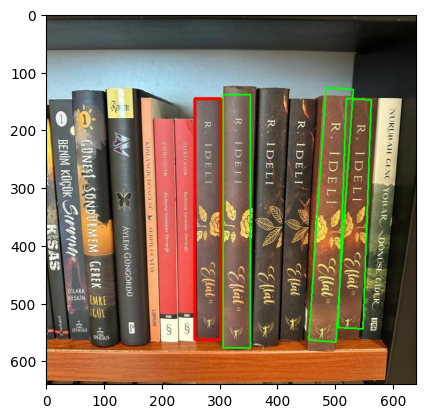

-------- Processing model 3 --------
Homography computed successfully


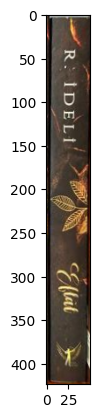

Best SSD val: 0.2210928201675415
New match found with 140/140 good matches. SSD: 0.2210928201675415.
Best SSD val: 0.3003726899623871
Value 0.3003726899623871 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.3003726899623871/0.03.
Total instances detected: 2


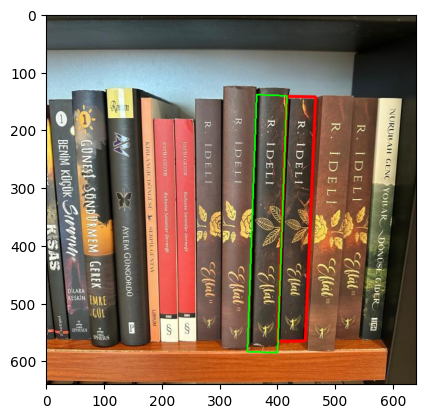

-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could n

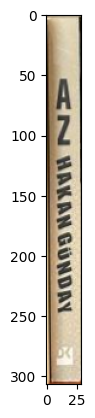

Best SSD val: 0.09916859865188599
New match found with 193/90 good matches. SSD: 0.09916859865188599.
Best SSD val: 0.15852512419223785
Not enough matches: 10/94. SSD: 0.15852512419223785.
Best SSD val: 0.1602076143026352
Not enough matches: 19/94. SSD: 0.1602076143026352.
Best SSD val: 0.1783711463212967
Not enough matches: 36/96. SSD: 0.1783711463212967.
Best SSD val: 0.18083946406841278
Not enough matches: 16/96. SSD: 0.18083946406841278.
Best SSD val: 0.19420507550239563
Not enough matches: 31/97. SSD: 0.19420507550239563.
Best SSD val: 0.19421301782131195
Not enough matches: 21/97. SSD: 0.19421301782131195.
Best SSD val: 0.2628285884857178
Not enough matches: 43/103. SSD: 0.2628285884857178.
Best SSD val: 0.2827208340167999
Value 0.2827208340167999 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.2827208340167999/0.03.
Total instances detected: 2


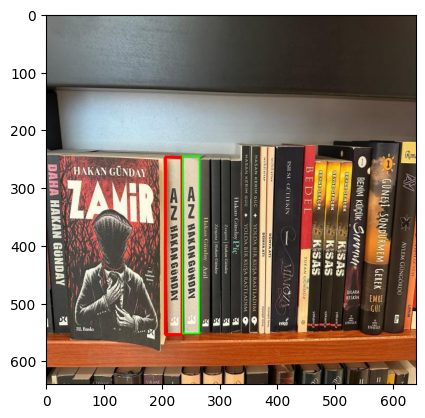

-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not

In [146]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.075
#hyst_th = (0.465, 0.80)
hyst_th = (0.03, 0.27)

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"-------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          main(model_path, scene_path, 
               grayscale=grayscale, 
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               cross_check=crosscheck, 
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED)